In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pylab as pl
%matplotlib inline

In [5]:
import os
import shutil
import pandas as pd

Name_data_set = "Student_Performance"
Surce_path    = r"C:\Users\mehdi\Documents\ML-GitHub-Projects\multple_lnear_regression\Student_Performance.csv"

if not os.path.exists(Name_data_set):
    if os.path.exists(Surce_path):
        print("Copying dataset to project directory...")
        shutil.copy(Surce_path , Name_data_set )
        print("Dataset successfully copied! ")
    else: 
        print(" Error: Dataset file not found at the source path.")
else: 
    print("Dataset already exists in project directory. Ready to use! ")


if os.path.exists(Name_data_set):
    df = pd.read_csv(Name_data_set)
    print("Data loaded successfully! ")
    print(df.head())

Dataset already exists in project directory. Ready to use! 
Data loaded successfully! 
   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  


In [6]:
df = pd.read_csv("Student_Performance")
df.head(10)

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0
5,3,78,No,9,6,61.0
6,7,73,Yes,5,6,63.0
7,8,45,Yes,4,6,42.0
8,5,77,No,8,2,61.0
9,4,89,No,4,0,69.0


In [7]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.583300,55.224800
std,2.589309,17.343152,1.695863,2.867348,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [8]:
cdf = df[['Hours Studied','Previous Scores','Sleep Hours','Sample Question Papers Practiced','Performance Index']]
cdf.head(10)

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,9,1,91.0
1,4,82,4,2,65.0
2,8,51,7,2,45.0
3,5,52,5,2,36.0
4,7,75,8,5,66.0
5,3,78,9,6,61.0
6,7,73,5,6,63.0
7,8,45,4,6,42.0
8,5,77,8,2,61.0
9,4,89,4,0,69.0


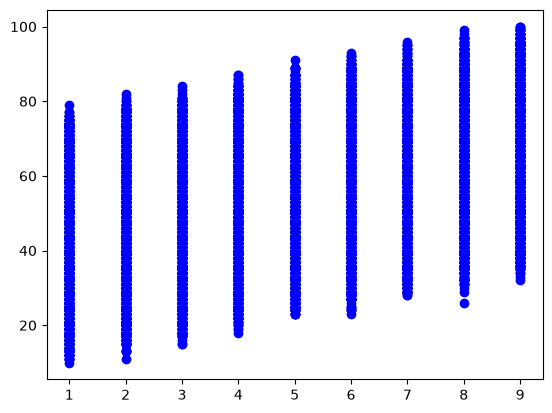

In [10]:
plt.scatter(
    cdf["Hours Studied"],
    cdf["Performance Index"],
    color="blue"
)

plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.show()

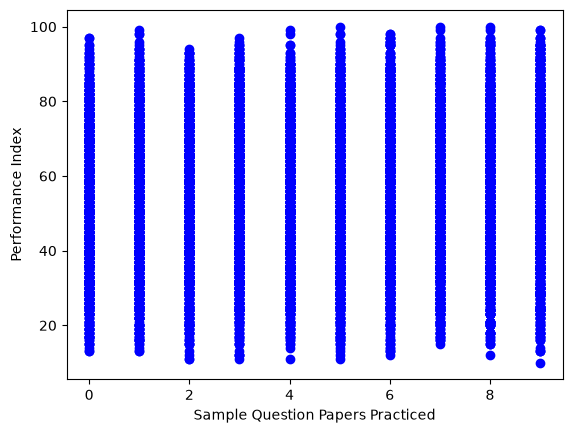

In [11]:
plt.scatter(
    cdf["Sample Question Papers Practiced"] ,
    cdf["Performance Index"] ,
    color = "blue"
)

plt.xlabel("Sample Question Papers Practiced")
plt.ylabel("Performance Index")
plt.show()

In [13]:
msk = np.random.rand(len(df)) > 0.8
train = cdf[msk]
test  = cdf[~msk]

print(f"train set cuont: {len(train)}")
print(f"test set cuont {len(test)}")

train set cuont: 2074
test set cuont 7926


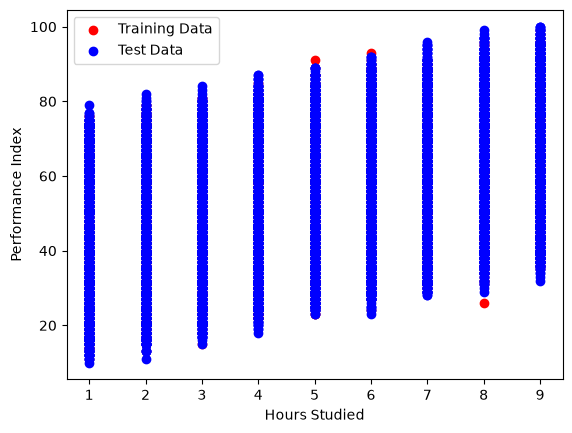

In [16]:
fig = plt.figure()
ax1 = fig.add_subplot(111)

ax1.scatter(train["Hours Studied"], train["Performance Index"],
            color="red", label="Training Data")

ax1.scatter(test["Hours Studied"], test["Performance Index"],
            color="blue", label="Test Data")

plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.legend()
plt.show()

In [17]:
from sklearn import linear_model
regr = linear_model.LinearRegression()
x = np.asanyarray(train[['Hours Studied','Previous Scores','Sleep Hours','Sample Question Papers Practiced',]])
y = np.asanyarray(train[['Performance Index']])
regr.fit (x,y)

print('Coefficients: ' , regr.coef_)
print('intercept: ' , regr.intercept_)

Coefficients:  [[2.83984336 1.01695668 0.44818001 0.19251331]]
intercept:  [-33.42885771]


In [19]:
x = np.asanyarray(test[['Hours Studied','Previous Scores','Sleep Hours','Sample Question Papers Practiced',]])
y = np.asanyarray(test[['Performance Index']])
y_hat = regr.predict(x)

print("Residual sum of squares: %.2f"
      % np.mean((y_hat - y) ** 2))

# Explained variance score: 1 is perfect prediction
print('Variance score: %.2f' % regr.score(x, y))

Residual sum of squares: 4.32
Variance score: 0.99
